# Computational complexity – Analysis

This notebook analyzes the computational complexity of the analysis functions in `features.py` and `statistics.py`, line by line and globally, using O(n) notation (S7). It also compares the unoptimized and optimized versions of the feature extraction and of the Fisher Discriminant Ratio (FDR).

Notation used in this notebook:
- **n**: number of sprouts (2,795 after cleaning).
- **L**: number of internodes of a sprout (at most 29).
- **F**: number of features (7).
- **K**: number of treatments (6).
- **T**: number of thresholds tested in the classification rule (4).

In [1]:
# Make the project root importable, because this notebook is inside src/<module>/
import sys, os, inspect, timeit
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
# this lets the notebook find the src folder, which is two levels up
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing.cleaning import preprocess
from src.analysis import features as ft
from src.analysis import statistics as st

df = preprocess(os.path.join(ROOT, 'data', 'raw', 'cjs.csv'))
df_feat = ft.add_features(df)
df_feat.shape

(2795, 43)

## `SpatialFeatures`

In [2]:
# inspect.getsource shows the code of the function, so I can analyze it here
print(inspect.getsource(ft.SpatialFeatures))

class SpatialFeatures(FeatureExtractor):
    """
    Spatial-domain features: size and variability of the internodes.
    """

    def extract(self):
        """
        Compute the spatial features of the sequence.

        cv_length is the normalized version of std_length (std / mean), so it
        measures how uneven the internodes are without depending on the size
        of the sprout.

        Returns
        -------
        dict
            max_length, mean_length, std_length, cv_length, energy and rms.
        """
        mean = np.mean(self.seq)
        std = np.std(self.seq)
        return {'max_length': np.max(self.seq),
                'mean_length': mean,
                'std_length': std,
                # cv is std divided by mean, I added it to normalize std like the professor asked in Lab 2
                'cv_length': std / mean,
                'energy': np.sum(self.seq**2),
                'rms': np.sqrt(np.mean(self.seq**2))}



*In this table, n = L, the number of internodes of one sprout (at most 29).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `mean = np.mean(self.seq)`: goes through the n internodes | O(n) |
| 2 | `std = np.std(self.seq)`: goes through the n internodes | O(n) |
| 3 | `np.max(self.seq)` | O(n) |
| 4 | `std / mean` | O(1) |
| 5 | `np.sum(self.seq**2)`: squares and adds the n values | O(n) |
| 6 | `np.sqrt(np.mean(self.seq**2))` | O(n) |

**Global complexity (one sprout):** several independent passes over the sequence, so **O(n)**.

## `FrequencyFeatures`

In [3]:
print(inspect.getsource(ft.FrequencyFeatures))

class FrequencyFeatures(FeatureExtractor):
    """
    Frequency-domain feature: shape of the sprout from its FFT.
    """

    def extract(self):
        """
        Compute the low-frequency ratio of the sequence.

        It is the share of the lowest frequency in the energy of the first half
        of the spectrum (without the DC value): close to 1 means a smooth arch,
        close to 0 means a zigzag. Sprouts with less than 4 internodes, or with
        all internodes equal, have no shape to analyze and get NaN.

        Returns
        -------
        dict
            low_freq_ratio.
        """
        if len(self.seq) < 4 or np.std(self.seq) < 1e-10:
            return {'low_freq_ratio': np.nan}
        spectrum = np.abs(scipy.fft.fft(self.seq))
        half = len(self.seq) // 2
        low_freq_ratio = spectrum[1]**2 / np.sum(spectrum[1:half+1]**2)
        return {'low_freq_ratio': low_freq_ratio}



*In this table, n = L, the number of internodes of one sprout (at most 29).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `if len(self.seq) < 4 or np.std(self.seq) < 1e-10:`: std goes through the n values | O(n) |
| 2 | `return {'low_freq_ratio': np.nan}` | O(1) |
| 3 | `scipy.fft.fft(self.seq)`: divide-and-conquer algorithm (S7) | O(n log n) |
| 4 | `np.abs(...)`: n values | O(n) |
| 5 | `half = len(self.seq) // 2` | O(1) |
| 6 | `np.sum(spectrum[1:half+1]**2)`: n/2 values | O(n) |
| 7 | `spectrum[1]**2 / ...` and `return` | O(1) |

**Global complexity (one sprout):** O(n) + O(n log n) + O(n) + O(n) = **O(n log n)**, dominated by the FFT. With the direct formula of the Discrete Fourier Transform (two nested loops) it would be O(n²).

## `extract_one`

In [4]:
print(inspect.getsource(ft.extract_one))

def extract_one(seq):
    """
    Compute all the features of one sprout using both extractor classes.

    Parameters
    ----------
    seq : numpy.ndarray
        Internode lengths of one sprout, without NaN.

    Returns
    -------
    dict
        The seven features of the sprout.
    """
    features = {}
    # Use both classes and join their results in one dictionary, this is polymorphism
    for Extractor in SpatialFeatures, FrequencyFeatures:
        features.update(Extractor(seq).extract())
    return features



*In this table, n = L, the number of internodes of one sprout (at most 29).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `features = {}` | O(1) |
| 2 | `for Extractor in SpatialFeatures, FrequencyFeatures:`: 2 iterations | O(1) |
| 3 | `Extractor(seq).extract()`: O(n) for the spatial class, O(n log n) for the frequency class | O(n log n) |
| 4 | `features.update(...)`: adds a few keys to the dictionary | O(1) |

**Global complexity (one sprout):** O(n) + O(n log n) = **O(n log n)**, dominated by the FFT.

## `extract_features_loop`

In [5]:
print(inspect.getsource(ft.extract_features_loop))

def extract_features_loop(df):
    """
    Extract the features of every sprout row by row (unoptimized version).

    It uses DataFrame.apply with axis=1, as in the Lab 2 notebook: for each
    row pandas builds a Series, removes the NaN and converts it to an array.

    Parameters
    ----------
    df : pandas.DataFrame
        Clean dataset.

    Returns
    -------
    pandas.DataFrame
        One row per sprout and one column per feature.
    """
    def row_features(row):
        """
        Compute the features of one row of the dataset, that is one sprout.
        """
        # dropna removes the internodes that don't exist, to_numpy() turns it into an array
        seq = row[INTERNODE_COLS].dropna().to_numpy().astype(float)
        return pd.Series(extract_one(seq))

    return df.apply(row_features, axis=1)[FEATURE_COLS]



*n = number of sprouts; L = number of internode columns (29).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `df.apply(row_features, axis=1)`: one call for each of the n sprouts | O(n) calls |
| 2 | `row[INTERNODE_COLS]`: pandas builds a new Series for each row | O(L) per sprout |
| 3 | `.dropna().to_numpy().astype(float)` | O(L) per sprout |
| 4 | `extract_one(seq)` | O(L log L) per sprout |
| 5 | `pd.Series(...)` and joining the n results into a table | O(n) |

**Global complexity:** n × O(L log L) = **O(n · L log L)**. Since L ≤ 29 is fixed, it is **O(n)**. The cost per sprout is high because pandas creates two Series objects for every row.

## `extract_features`

In [6]:
print(inspect.getsource(ft.extract_features))

def extract_features(df):
    """
    Extract the features of every sprout (optimized version).

    The internode columns are converted to one NumPy matrix only once. The
    spatial features are computed for all sprouts at the same time with
    vectorized NaN-aware NumPy functions, and the frequency feature is computed
    over NumPy rows, without building a pandas Series for each sprout.

    Parameters
    ----------
    df : pandas.DataFrame
        Clean dataset.

    Returns
    -------
    pandas.DataFrame
        One row per sprout and one column per feature (same values as
        extract_features_loop).
    """
    X = df[INTERNODE_COLS].to_numpy(dtype=float)
    # np.nanmean, np.nanstd, np.nanmax and np.nansum work like np.mean and np.std, but they skip the NaN, so I can use them on the whole matrix at once
    mean = np.nanmean(X, axis=1)
    std = np.nanstd(X, axis=1)
    features = pd.DataFrame({'max_length': np.nanmax(X, axis=1),
                             'mean_leng

*n = number of sprouts; L = number of internode columns (29).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `X = df[INTERNODE_COLS].to_numpy(dtype=float)`: one matrix of n × 29, created once | O(n · L) |
| 2 | `np.nanmean`, `np.nanstd`, `np.nanmax`, `np.nansum`, `np.sqrt(...)` with `axis=1`: vectorized passes over the matrix | O(n · L) |
| 3 | `std / mean` for all sprouts | O(n) |
| 4 | `pd.DataFrame({...})` | O(n) |
| 5 | list comprehension: for each of the n rows, `row[~np.isnan(row)]` and `FrequencyFeatures(...).extract()` | n × O(L log L) |

**Global complexity:** O(n · L) + O(n · L log L) = **O(n · L log L)**, that is, **O(n)** with L ≤ 29. Same order as `extract_features_loop`, but with a much smaller constant: the spatial features are computed for all sprouts at once in NumPy, and no pandas Series is built per sprout.

## `group_test`

In [7]:
print(inspect.getsource(st.group_test))

def group_test(df, features, alpha_normal=0.05):
    """
    Compare the six treatments for each feature.

    Same rule as in S5: Shapiro-Wilk is applied to each group, and if any group
    is not normal Kruskal-Wallis is used; otherwise, one-way ANOVA.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the TR_code column and the features.
    features : list of str
        Features to test.
    alpha_normal : float, optional
        Significance level of the normality test. Default 0.05.

    Returns
    -------
    pandas.DataFrame
        For each feature: test used, statistic and p-value.
    """
    # Shapiro-Wilk checks if each treatment is normal, then I use ANOVA or Kruskal-Wallis
    # Same rule as in S5: if any group is not normal, use Kruskal-Wallis
    rows = []
    for feature in features:
        # Split the sprouts into the 6 treatments
        groups = [df[df['TR_code'] == i][feature].dropna() for i in range(6)]
        shapiro_p = [shapiro(g

*n = number of sprouts; F = number of features (7); K = number of treatments (6).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `for feature in features:` | F iterations |
| 2 | `groups = [df[df['TR_code'] == i][feature].dropna() for i in range(6)]`: filters the n sprouts once per treatment | O(K · n) |
| 3 | `shapiro(g)` for each group: works with the sorted values of the group | O(n log n) in total |
| 4 | `kruskal(*groups)`: sorts all the values to compute their ranks | O(n log n) |
| 5 | `f_oneway(*groups)` (only if all groups are normal): means and variances | O(n) |
| 6 | `rows.append(...)` | O(1) |

**Global complexity:** F × (O(K · n) + O(n log n)) = **O(F · (K · n + n log n))**, that is, **O(n log n)** with F and K fixed. The dominant operation is sorting the values for the tests.

## `compare_two_groups`

In [8]:
print(inspect.getsource(st.compare_two_groups))

def compare_two_groups(df, features, code_a, code_b):
    """
    Compare two treatments with Kruskal-Wallis (non-normal data).

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the TR_code column and the features.
    features : list of str
        Features to compare.
    code_a, code_b : int
        TR_code of the two treatments (e.g. 4 = control, 5 = methanol_control).

    Returns
    -------
    pandas.DataFrame
        For each feature: statistic and p-value.
    """
    # Compare the two control groups, control and methanol_control.
    # Methanol is only the solvent, so in theory both groups should be the same.
    # Kruskal-Wallis with 2 groups is used because the data are not normal
    a = df[df['TR_code'] == code_a]
    b = df[df['TR_code'] == code_b]
    rows = []
    for feature in features:
        stat, p_value = kruskal(a[feature].dropna(), b[feature].dropna())
        rows.append({'feature': feature, 'statistic': stat, 'p_value': p_value})

*n = number of sprouts; F = number of features (7).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `a = df[df['TR_code'] == code_a]`, `b = ...`: two filters | O(n) |
| 2 | `for feature in features:` | F iterations |
| 3 | `kruskal(a[feature].dropna(), b[feature].dropna())`: ranks the values, which requires sorting | O(n log n) |
| 4 | `rows.append(...)` | O(1) |

**Global complexity:** O(n) + F × O(n log n) = **O(F · n log n)**, that is, **O(n log n)** with F = 7 fixed.

## `fdr_loop`

In [9]:
print(inspect.getsource(st.fdr_loop))

def fdr_loop(df, features):
    """
    Fisher Discriminant Ratio of each feature (unoptimized version).

    For each feature and each treatment, the rows of that treatment are
    filtered again from the whole dataset, as in the Lab 2 notebook.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the TR_code column and the features.
    features : list of str
        Features to evaluate.

    Returns
    -------
    pandas.Series
        FDR of each feature, sorted from highest to lowest.
    """
    # Fisher Discriminant Ratio for each feature, calculated one feature at a time.
    # FDR = dispersion between treatments / dispersion within treatments.
    # A high FDR means the groups are far apart and compact.
    # I calculate the FDR one feature at a time and not with matrices like in S5, because with matrices it gave negative values since the features are very correlated
    fdr = {}
    for feature in features:
        data = df[['TR_code', feature]].dr

*n = number of sprouts; F = number of features (7); K = number of treatments (6).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `for feature in features:` | F iterations |
| 2 | `data = df[['TR_code', feature]].dropna()` | O(n) |
| 3 | `overall_mean = data[feature].mean()` | O(n) |
| 4 | `group_means = data.groupby('TR_code')[feature].mean()` | O(n) |
| 5 | `for k, mean_k in group_means.items():` | K iterations |
| 6 | `x = data[data['TR_code'] == k][feature]`: filters the n sprouts again for each treatment | O(n) |
| 7 | `within += ...`, `between += ...` | O(n / K) on average |
| 8 | `fdr[feature] = between / within` | O(1) |

**Global complexity:** F × (O(n) + K × O(n)) = **O(F · K · n)**. With F and K fixed it is O(n), but the n sprouts are visited K times for every feature.

## `fdr`

In [10]:
print(inspect.getsource(st.fdr))

def fdr(df, features):
    """
    Fisher Discriminant Ratio of each feature (optimized version).

    One groupby pass computes the count, mean and variance of every feature in
    every treatment at the same time, so the data is not filtered again for
    each group. FDR = dispersion between treatments / dispersion within them.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the TR_code column and the features.
    features : list of str
        Features to evaluate.

    Returns
    -------
    pandas.Series
        FDR of each feature, sorted from highest to lowest (same values as
        fdr_loop).
    """
    # I get the count, mean and var of all the groups in one pass, so the data is not filtered again for each treatment
    grouped = df.groupby('TR_code')[features]
    count = grouped.count()
    mean = grouped.mean()
    # ddof=0 makes the variance use the same formula as fdr_loop
    var = grouped.var(ddof=0)
    overall_mean = (count * mean).su

*n = number of sprouts; F = number of features (7); K = number of treatments (6).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `grouped = df.groupby('TR_code')[features]`: puts each sprout in the group of its treatment in one pass | O(n) |
| 2 | `count = grouped.count()` | O(F · n) |
| 3 | `mean = grouped.mean()` | O(F · n) |
| 4 | `var = grouped.var(ddof=0)` | O(F · n) |
| 5 | `overall_mean`, `within`, `between`: operations on K × F tables | O(K · F) |
| 6 | `.sort_values(...)`: sorts F values | O(F log F) |

**Global complexity:** **O(F · n)**. With F and K fixed it is also O(n), but the factor K disappears: the sprouts are grouped once instead of being filtered once per treatment.

## `auc_one_vs_rest`

In [11]:
print(inspect.getsource(st.auc_one_vs_rest))

def auc_one_vs_rest(df, features):
    """
    ROC-AUC of each feature for each treatment against the rest (as in S5).

    If the AUC is below 0.5, 1 - AUC is used, because the feature separates the
    groups in the opposite direction.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the TR_code column and the features.
    features : list of str
        Features to evaluate.

    Returns
    -------
    pandas.DataFrame
        One row per feature and one column per treatment.
    """
    # Empty table: one row per feature, one column per treatment
    table = pd.DataFrame(index=features, columns=list(TREATMENTS.values()),
                         dtype=float)
    for feature in features:
        data = df[['TR_code', feature]].dropna()
        # AUC one versus rest: each treatment is 1 and all the others are 0
        for class_idx, name in TREATMENTS.items():
            target = np.where(data['TR_code'] == class_idx, 1, 0)
            auc = roc_auc_sc

*n = number of sprouts; F = number of features (7); K = number of treatments (6).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `table = pd.DataFrame(...)`: empty table of F × K | O(F · K) |
| 2 | `for feature in features:` | F iterations |
| 3 | `data = df[['TR_code', feature]].dropna()` | O(n) |
| 4 | `for class_idx, name in TREATMENTS.items():` | K iterations |
| 5 | `target = np.where(...)` | O(n) |
| 6 | `roc_auc_score(target, data[feature])`: sorts the values to build the ROC curve | O(n log n) |
| 7 | `table.loc[...] = ...` | O(1) |

**Global complexity:** F × K × O(n log n) = **O(F · K · n log n)**, that is, **O(n log n)** with F = 7 and K = 6 fixed.

## `auc_control_vs_treated`

In [12]:
print(inspect.getsource(st.auc_control_vs_treated))

def auc_control_vs_treated(df, features):
    """
    ROC-AUC of each feature to separate control from treated sprouts.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the TR_code column and the features.
    features : list of str
        Features to evaluate.

    Returns
    -------
    pandas.Series
        AUC of each feature, sorted from highest to lowest.
    """
    # 1 is control, that is TR_code 4 and 5, and 0 is treated, that is TR_code 0 to 3
    is_control = np.where(df['TR_code'] >= 4, 1, 0)
    result = {}
    for feature in features:
        mask = df[feature].notna().to_numpy()
        auc = roc_auc_score(is_control[mask], df[feature][mask])
        result[feature] = auc if auc >= .5 else 1 - auc
    # Sort from best to worst
    return pd.Series(result).sort_values(ascending=False)



*n = number of sprouts; F = number of features (7).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `is_control = np.where(df['TR_code'] >= 4, 1, 0)` | O(n) |
| 2 | `for feature in features:` | F iterations |
| 3 | `mask = df[feature].notna().to_numpy()` | O(n) |
| 4 | `roc_auc_score(...)`: sorts the values | O(n log n) |
| 5 | `pd.Series(result).sort_values(...)`: sorts F values | O(F log F) |

**Global complexity:** O(n) + F × O(n log n) = **O(F · n log n)**, that is, **O(n log n)**.

## `threshold_rule`

In [13]:
print(inspect.getsource(st.threshold_rule))

def threshold_rule(df, feature, thresholds):
    """
    Evaluate a simple rule: a sprout is a control if feature > threshold.

    Parameters
    ----------
    df : pandas.DataFrame
        Dataset with the TR_code column and the feature.
    feature : str
        Feature used by the rule.
    thresholds : list of float
        Thresholds to test.

    Returns
    -------
    pandas.DataFrame
        TP, TN, FP, FN, accuracy, precision, recall and F1 for each threshold
        (control is the positive class).
    """
    y_true = np.where(df['TR_code'] >= 4, 1, 0)
    values = df[feature].to_numpy()
    results = []
    for threshold in thresholds:
        y_pred = np.where(values > threshold, 1, 0)
        TP = np.sum((y_pred == 1) & (y_true == 1))   # control predicted as control
        TN = np.sum((y_pred == 0) & (y_true == 0))   # treated predicted as treated
        FP = np.sum((y_pred == 1) & (y_true == 0))   # treated predicted as control
        FN = np.sum((y_pred == 0) & (

*n = number of sprouts; T = number of thresholds (4).*

| Line | Code | Complexity |
|---|---|---|
| 1 | `y_true = np.where(...)`, `values = df[feature].to_numpy()` | O(n) |
| 2 | `for threshold in thresholds:` | T iterations |
| 3 | `y_pred = np.where(values > threshold, 1, 0)` | O(n) |
| 4 | the four `np.sum(...)` for TP, TN, FP and FN | O(n) |
| 5 | accuracy, precision, recall and F1 | O(1) |
| 6 | `pd.DataFrame(results)` | O(T) |

**Global complexity:** O(n) + T × O(n) = **O(T · n)**, that is, **O(n)** with T = 4 fixed.

## Optimization 1: feature extraction

`extract_features_loop` uses `apply(axis=1)`: for every sprout pandas builds a Series, removes the NaN and converts it to an array. `extract_features` converts the internode columns to one NumPy matrix only once, computes the spatial features for all sprouts at the same time (vectorization, as in the `np.mean` example of S7) and computes the FFT over NumPy rows. Both give the same values:

In [14]:
np.allclose(ft.extract_features_loop(df).to_numpy(), ft.extract_features(df).to_numpy(), equal_nan=True)

True

In [15]:
def time_vs_n(func, make_input, sizes, repeat=3):
    """Return the best execution time of func for each input size (as in S7, with timeit)."""
    times = []
    for n in sizes:
        data = make_input(n)
        times.append(min(timeit.repeat(lambda: func(data), number=1, repeat=repeat)))
    return times

sizes = [500, 1000, 2000, 4000, 8000]
make_input = lambda n: df.sample(n, replace=True, random_state=0).reset_index(drop=True)

t_loop = time_vs_n(ft.extract_features_loop, make_input, sizes, repeat=1)
t_opt = time_vs_n(ft.extract_features, make_input, sizes)

feat_times = pd.DataFrame({'n': sizes, 'loop (s)': t_loop, 'optimized (s)': t_opt,
                           'speed-up': np.array(t_loop) / np.array(t_opt)})
feat_times.round(4)

,n,loop (s),optimized (s),speed-up
0,500,0.2634,0.0056,46.9047
1,1000,0.5263,0.0104,50.5888
2,2000,1.0705,0.0198,54.0190
3,4000,2.4165,0.0383,63.0549
4,8000,4.2129,0.0753,55.9658


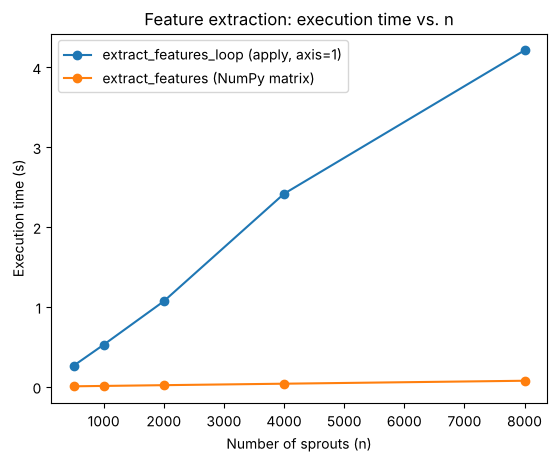

In [16]:
plt.plot(sizes, t_loop, 'o-', label='extract_features_loop (apply, axis=1)')
plt.plot(sizes, t_opt, 'o-', label='extract_features (NumPy matrix)')
plt.xlabel('Number of sprouts (n)')
plt.ylabel('Execution time (s)')
plt.title('Feature extraction: execution time vs. n')
plt.legend()
plt.show()

**Comparison.** Both versions are **O(n · L log L)**, that is, **O(n)** with L ≤ 29: each sprout is processed once and the FFT dominates the cost per sprout. However, the optimized version was about **50 times faster**. `extract_features_loop` builds two pandas Series for each of the n sprouts and computes the spatial features one sprout at a time, while `extract_features` creates one NumPy matrix only once and computes the spatial features of all sprouts at the same time (vectorization, as in the `np.mean` example of S7). The order is the same; the constant is much smaller.

## Optimization 2: Fisher Discriminant Ratio

`fdr_loop` filters the rows of each treatment from the whole dataset inside a loop (K filters of n rows for every feature). `fdr` computes the count, mean and variance of all features and all treatments in one `groupby` pass (S7: avoiding duplicate calculations). Both give the same values:

In [17]:
np.allclose(st.fdr_loop(df_feat, ft.FEATURE_COLS).sort_index(), st.fdr(df_feat, ft.FEATURE_COLS).sort_index())

True

In [18]:
make_input = lambda n: df_feat.sample(n, replace=True, random_state=0).reset_index(drop=True)
sizes = [1000, 2000, 4000, 8000, 16000]

t_loop = time_vs_n(lambda d: st.fdr_loop(d, ft.FEATURE_COLS), make_input, sizes)
t_opt = time_vs_n(lambda d: st.fdr(d, ft.FEATURE_COLS), make_input, sizes)

pd.DataFrame({'n': sizes, 'loop (s)': t_loop, 'optimized (s)': t_opt,
              'speed-up': np.array(t_loop) / np.array(t_opt)}).round(4)

,n,loop (s),optimized (s),speed-up
0,1000,0.0185,0.0024,7.5514
1,2000,0.0196,0.0024,8.1349
2,4000,0.0303,0.0026,11.4907
3,8000,0.0224,0.0031,7.2790
4,16000,0.0232,0.0034,6.8035


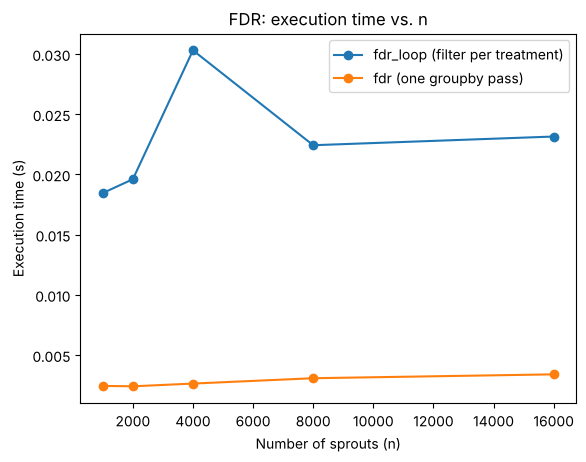

In [19]:
plt.plot(sizes, t_loop, 'o-', label='fdr_loop (filter per treatment)')
plt.plot(sizes, t_opt, 'o-', label='fdr (one groupby pass)')
plt.xlabel('Number of sprouts (n)')
plt.ylabel('Execution time (s)')
plt.title('FDR: execution time vs. n')
plt.legend()
plt.show()

**Comparison.** With F and K fixed, both versions are O(n). But `fdr_loop` is **O(F · K · n)**, because it filters the n sprouts once for each treatment and each feature, while `fdr` is **O(F · n)**, because `groupby` puts every sprout in its group in a single pass (S7: avoiding duplicate calculations). The factor K = 6 disappears, which agrees with the measured speed-up of about **7 times**. If the study had more treatments, the difference would grow, because the loop version depends on K and the optimized one does not.